
Training: No Regularization
Epoch 1/15
375/375 [==============================] - 3s 3ms/step - loss: 0.3055 - accuracy: 0.9133 - val_loss: 0.1423 - val_accuracy: 0.9603
Epoch 2/15
375/375 [==============================] - 1s 3ms/step - loss: 0.1136 - accuracy: 0.9661 - val_loss: 0.1078 - val_accuracy: 0.9692
Epoch 3/15
375/375 [==============================] - 1s 2ms/step - loss: 0.0736 - accuracy: 0.9773 - val_loss: 0.0915 - val_accuracy: 0.9734
Epoch 4/15
375/375 [==============================] - 1s 2ms/step - loss: 0.0529 - accuracy: 0.9840 - val_loss: 0.0946 - val_accuracy: 0.9732
Epoch 5/15
375/375 [==============================] - 1s 3ms/step - loss: 0.0388 - accuracy: 0.9880 - val_loss: 0.0844 - val_accuracy: 0.9754
Epoch 6/15
375/375 [==============================] - 1s 2ms/step - loss: 0.0285 - accuracy: 0.9909 - val_loss: 0.0773 - val_accuracy: 0.9789
Epoch 7/15
375/375 [==============================] - 1s 2ms/step - loss: 0.0242 - accuracy: 0.9922 - val_loss: 0.0810 

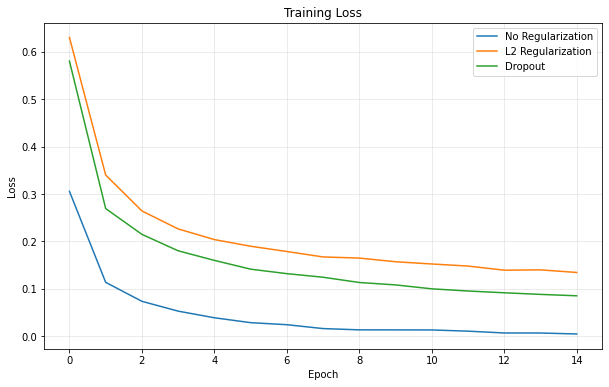

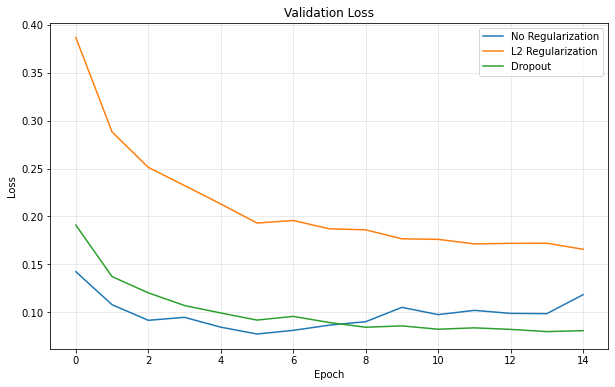

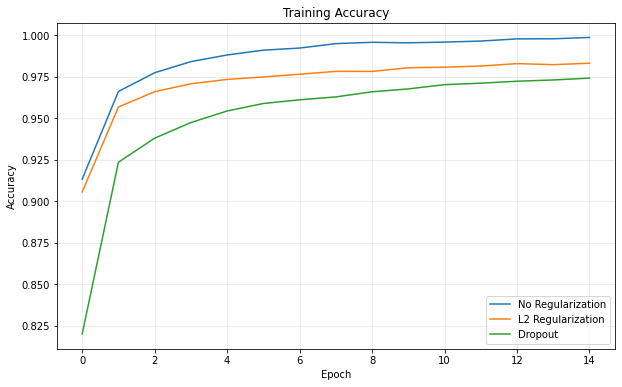

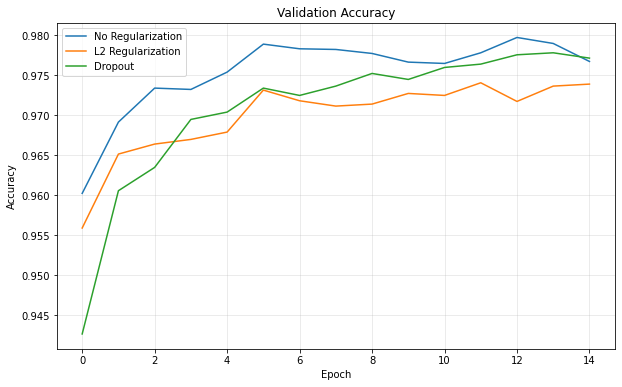


Final Validation Performance:
No Regularization    | Val Loss: 0.1183 | Val Accuracy: 0.9768
L2 Regularization    | Val Loss: 0.1657 | Val Accuracy: 0.9739
Dropout              | Val Loss: 0.0807 | Val Accuracy: 0.9772


In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

def build_model(regularization=None):
    model = tf.keras.Sequential([
        tf.keras.layers.Flatten(input_shape=(28, 28)),

        tf.keras.layers.Dense(
            256,
            activation="relu",
            kernel_regularizer=(
                tf.keras.regularizers.l2(0.001)
                if regularization == "l2" else None
            )
        ),

        tf.keras.layers.Dropout(
            0.5 if regularization == "dropout" else 0.0
        ),

        tf.keras.layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=(
                tf.keras.regularizers.l2(0.001)
                if regularization == "l2" else None
            )
        ),

        tf.keras.layers.Dropout(
            0.5 if regularization == "dropout" else 0.0
        ),

        tf.keras.layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

histories = {}

configs = {
    "No Regularization": None,
    "L2 Regularization": "l2",
    "Dropout": "dropout"
}

for name, reg in configs.items():
    print(f"\nTraining: {name}")

    model = build_model(reg)

    history = model.fit(
        x_train,
        y_train,
        validation_split=0.2,
        epochs=15,
        batch_size=128,
        verbose=1
    )

    histories[name] = history

plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(
        history.history["loss"],
        label=name
    )

plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(
        history.history["val_loss"],
        label=name
    )

plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(
        history.history["accuracy"],
        label=name
    )

plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(
        history.history["val_accuracy"],
        label=name
    )

plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\nFinal Validation Performance:")

for name, history in histories.items():
    val_loss = history.history["val_loss"][-1]
    val_acc = history.history["val_accuracy"][-1]

    print(
        f"{name:20s} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )
